# Iteration 3: feature selection and holdout evaluation

This notebook runs five stratified 70/15/15 splits. It compares **RFE with CART** and **CART importance ranking**, each retaining exactly **20 source predictors**. Selected continuous measurements receive Yeo-Johnson transformation followed by standardization; encoded categories receive one-hot encoding.

The source labels are **0 = gallstones present, 1 = absent**. For these experiments only, the modeling target is **1 = present, 0 = absent**. Thus ROC-AUC, recall and false-negative rate refer to gallstone cases. Source files and the older runners are unchanged.

All learned steps stay inside estimator pipelines, including each inner stacking fold. Validation chooses a model/selector combination by ROC-AUC, then accuracy, then lower FNR. The chosen pipeline is refitted on train + validation and tested once per seed. These overlapping splits describe stability, not independent confidence intervals.


In [ ]:
from pathlib import Path
import sys
from time import perf_counter
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.metrics import roc_auc_score, average_precision_score

import warnings
warnings.filterwarnings("ignore")

ROOT = next(p.resolve() for p in [Path.cwd(), Path.cwd() / "INFOSYS722/Iteration3_OpenStack"]
            if (p / "modeling.py").exists() and (p / "dataset_gallstone").exists())
sys.path.insert(0, str(ROOT))
from utils import (DEFAULT_SEEDS, load_data, metric_row, prediction_rows,
                   make_evaluation_model, selected_feature_table, continuous_columns)
from modeling import MODEL_NAMES

SEEDS = list(DEFAULT_SEEDS)
MODELS = list(MODEL_NAMES)
SELECTORS = ["rfe", "cart"]
TOP_K = 20
THRESHOLD = 0.5
TARGET = "gallstone_status"
OUTPUT = ROOT / "output" / "notebook_evaluation"
OUTPUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")


## 1. Load data and define the positive class

Only the modeling target is recoded. Prediction exports retain both the original source code and the binary disease indicator. Encoded categories are excluded from Yeo-Johnson and standardization.


In [2]:
X, source_y = load_data(ROOT / "dataset_gallstone", TARGET, ["record_id"])
y = source_y.eq(0).astype(int).rename("gallstones_present")
assert set(y.unique()) == {0, 1}
assert X.shape[1] >= TOP_K
display(pd.DataFrame({"source_code": [0, 1], "category": ["Present", "Absent"],
                      "model_target": [1, 0], "count": [int(y.sum()), int((1-y).sum())]}))
print(f"{len(X)} rows, {X.shape[1]} source predictors; selecting {TOP_K}.")


,source_code,category,model_target,count
0,0,Present,1,161
1,1,Absent,0,158


319 rows, 38 source predictors; selecting 20.


## 2. Stratified 70/15/15 splits

The 30% reserve is split equally into validation and test, stratifying both operations by the label. With 319 rows, each seed produces 223 training, 48 validation and 48 test rows. Source-row membership is saved.


In [3]:
splits, split_rows = {}, []
for seed in SEEDS:
    train, reserve = train_test_split(X.index, test_size=0.30, stratify=y, random_state=seed)
    valid, test = train_test_split(reserve, test_size=0.50, stratify=y.loc[reserve], random_state=seed)
    assert not (set(train) & set(valid) or set(train) & set(test) or set(valid) & set(test))
    assert len(train) + len(valid) + len(test) == len(X)
    splits[seed] = {"train": train, "validation": valid, "test": test}
    folder = OUTPUT / f"seed_{seed}"
    folder.mkdir(exist_ok=True)
    membership = pd.concat([
        pd.DataFrame({"source_row": indices, "split": label,
                      "source_target": source_y.loc[indices].to_numpy(),
                      "gallstones_present": y.loc[indices].to_numpy()})
        for label, indices in splits[seed].items()
    ])
    membership.to_csv(folder / "split_membership.csv", index=False)
    for label, indices in splits[seed].items():
        split_rows.append({"seed": seed, "split": label, "rows": len(indices),
                           "present": int(y.loc[indices].sum()),
                           "absent": int((1-y.loc[indices]).sum())})
display(pd.DataFrame(split_rows))


,seed,split,rows,present,absent
0,42,train,223,113,110
1,42,validation,48,24,24
2,42,test,48,24,24
3,7,train,223,113,110
4,7,validation,48,24,24
5,7,test,48,24,24
6,21,train,223,113,110
7,21,validation,48,24,24
8,21,test,48,24,24
9,84,train,223,113,110


In [4]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# FEATURE IMPORTANCE ACROSS ALL HOLDOUT SEEDS
# ============================================================

importance_rows = []

for seed in SEEDS:

    train_idx = splits[seed]["train"]
    valid_idx = splits[seed]["validation"]

    X_train = X.loc[train_idx]
    y_train = y.loc[train_idx]

    X_valid = X.loc[valid_idx]
    y_valid = y.loc[valid_idx]

    # --------------------------------------------------------
    # Fit Random Forest
    # --------------------------------------------------------
    rf = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        class_weight="balanced",
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    # --------------------------------------------------------
    # Extract feature importance
    # --------------------------------------------------------
    for feature, score in zip(
        X.columns,
        rf.feature_importances_
    ):
        importance_rows.append({
            "seed": seed,
            "feature": feature,
            "importance": score
        })


# ============================================================
# AGGREGATE IMPORTANCE ACROSS SEEDS
# ============================================================

importance_df = pd.DataFrame(importance_rows)

importance_summary = (
    importance_df
    .groupby("feature")["importance"]
    .agg(
        mean_importance="mean",
        std_importance="std"
    )
    .reset_index()
    .sort_values(
        "mean_importance",
        ascending=False
    )
)

display(importance_summary)

,feature,mean_importance,std_importance
9,crp,0.156508,0.013450
35,vitamin_d,0.077223,0.010050
3,ast,0.040717,0.005027
11,ecf_tbw,0.039132,0.007948
24,lm_pct,0.036008,0.006390
28,tbfr_pct,0.034257,0.007572
12,ecw,0.032140,0.007719
26,obesity_pct,0.030528,0.002447
19,hgb,0.029128,0.003667
1,alp,0.028638,0.002091


In [19]:
# ============================================================
# SETTINGS
# ============================================================

# Candidate numbers of features to compare
# Example: 3, 4, ..., all available features
K_VALUES = range(3, X.shape[1] + 1)

rfe_ranking_rows = []
evaluation_rows = []


# ============================================================
# RFE + TOP-K EVALUATION FOR EACH SEED
# ============================================================

for seed in SEEDS:

    train_idx = splits[seed]["train"]
    valid_idx = splits[seed]["validation"]

    X_train = X.loc[train_idx]
    y_train = y.loc[train_idx]

    X_valid = X.loc[valid_idx]
    y_valid = y.loc[valid_idx]


    # --------------------------------------------------------
    # 1. Create estimator used by RFE
    # --------------------------------------------------------
    rfe_estimator = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        class_weight="balanced",
        n_jobs=-1
    )


    # --------------------------------------------------------
    # 2. Rank ALL features
    #
    # n_features_to_select=1 makes RFE continue until one
    # feature remains, giving a complete ranking.
    #
    # ranking = 1 -> strongest feature
    # ranking = 2 -> second strongest
    # etc.
    # --------------------------------------------------------
    rfe = RFE(
        estimator=rfe_estimator,
        n_features_to_select=1,
        step=1
    )

    rfe.fit(X_train, y_train)


    # Save ranking
    ranking_df = pd.DataFrame({
        "seed": seed,
        "feature": X.columns,
        "rfe_rank": rfe.ranking_
    })

    rfe_ranking_rows.append(ranking_df)


    # --------------------------------------------------------
    # 3. Evaluate different Top-K subsets
    # --------------------------------------------------------
    for k in K_VALUES:

        selected_features = ranking_df.loc[
            ranking_df["rfe_rank"] <= k,
            "feature"
        ].tolist()


        # New RF model trained using only Top-K features
        model = RandomForestClassifier(
            n_estimators=500,
            random_state=seed,
            class_weight="balanced",
            n_jobs=-1
        )

        model.fit(
            X_train[selected_features],
            y_train
        )


        # Validation probabilities
        valid_prob = model.predict_proba(
            X_valid[selected_features]
        )[:, 1]


        roc_auc = roc_auc_score(
            y_valid,
            valid_prob
        )

        avg_precision = average_precision_score(
            y_valid,
            valid_prob
        )


        evaluation_rows.append({
            "seed": seed,
            "n_features": k,
            "roc_auc": roc_auc,
            "average_precision": avg_precision,
            "selected_features": selected_features
        })


# ============================================================
# COMBINE RESULTS
# ============================================================

rfe_rankings = pd.concat(
    rfe_ranking_rows,
    ignore_index=True
)

rfe_evaluation = pd.DataFrame(
    evaluation_rows
)

In [20]:
# ============================================================
# FEATURE RANKING ACROSS SEEDS
# ============================================================

ranking_summary = (
    rfe_rankings
    .groupby("feature")
    .agg(
        mean_rank=("rfe_rank", "mean"),
        std_rank=("rfe_rank", "std"),
        min_rank=("rfe_rank", "min"),
        max_rank=("rfe_rank", "max")
    )
    .reset_index()
    .sort_values("mean_rank")
)

display(ranking_summary)

,feature,mean_rank,std_rank,min_rank,max_rank
35,vitamin_d,1.4,0.894427,1,3
9,crp,1.8,0.447214,1,2
24,lm_pct,3.6,1.341641,2,5
3,ast,6.6,2.073644,4,9
26,obesity_pct,7.6,3.911521,3,13
12,ecw,8.0,5.916080,3,17
28,tbfr_pct,8.6,6.188699,4,19
11,ecf_tbw,9.8,4.969909,5,18
19,hgb,10.6,4.393177,6,17
31,tfc,10.6,2.073644,8,13


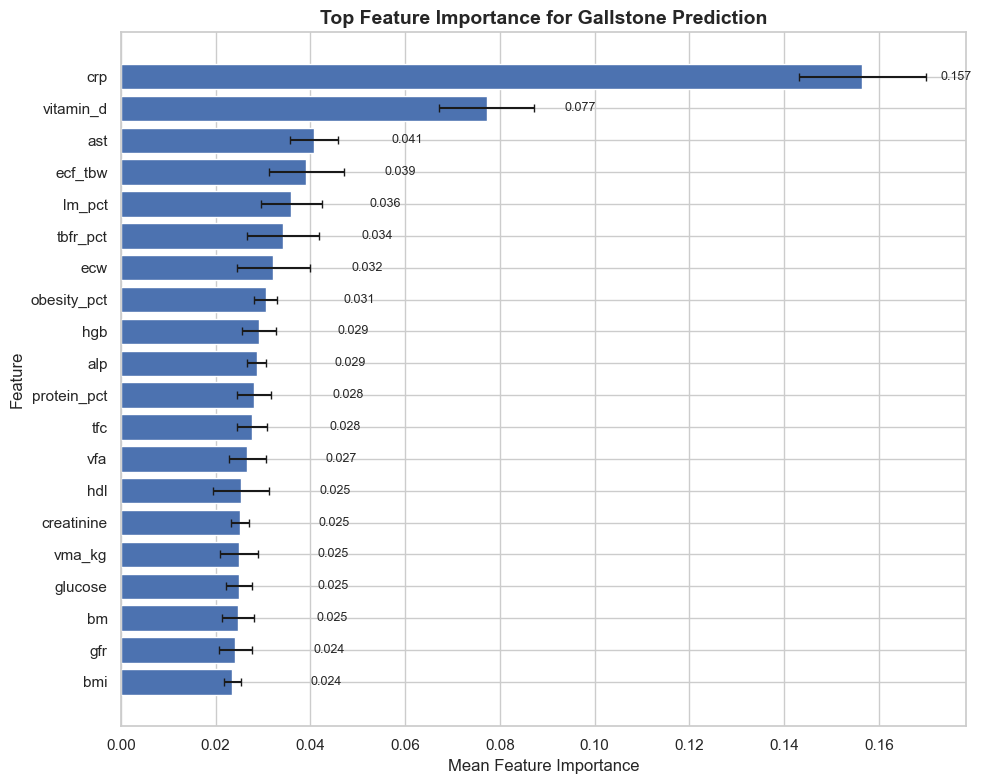

In [ ]:

TOP_N = 20

plot_importance = (
    importance_summary
    .head(TOP_N)
    .sort_values(
        "mean_importance",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

bars = ax.barh(
    plot_importance["feature"],
    plot_importance["mean_importance"],
    xerr=plot_importance["std_importance"],
    capsize=3
)

# ------------------------------------------------------------
# Add importance score labels
# ------------------------------------------------------------

for bar, score in zip(
    bars,
    plot_importance["mean_importance"]
):
    ax.text(
        bar.get_width() + 0.0165,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.3f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top Feature Importance for Gallstone Prediction",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Mean Feature Importance")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

## 3. Feature selection and validation comparison

Each candidate imputes training data, selects 20 raw predictors, transforms continuous features and fits the classifier. **RFE** removes the least important CART predictors iteratively; **CART** selects the 20 highest impurity importances directly. A CART tree may assign zero importance to some retained fields when fewer than 20 have positive importance; selection does not establish clinical relevance.

The existing logistic regression, random forest, XGBoost, LightGBM and stacking settings are reused. Stacking fits a complete selection/transformation pipeline inside each base learner's inner folds. No test data are used to select a configuration.


In [6]:
def score(seed, name, selection, evaluation, target, probability, seconds):
    row = metric_row(seed, name, evaluation, target, probability, seconds)
    row["selection"] = selection
    row["fnr"] = row["FN"] / (row["FN"] + row["TP"])
    return row

validation_rows, winners = [], {}
for seed in SEEDS:
    train, valid = splits[seed]["train"], splits[seed]["validation"]
    candidates = {}
    seed_rows = []
    for selection in SELECTORS:
        for name in MODELS:
            start = perf_counter()
            fitted = make_evaluation_model(name, X, seed, selection, TOP_K)
            fitted.fit(X.loc[train], y.loc[train])
            probability = fitted.predict_proba(X.loc[valid])[:, list(fitted.classes_).index(1)]
            row = score(seed, name, selection, "validation", y.loc[valid], probability,
                        perf_counter() - start)
            seed_rows.append(row)
            candidates[(selection, name)] = fitted
            features = selected_feature_table(fitted)
            assert features.groupby("base_model").selected.sum().eq(TOP_K).all()
            features.to_csv(OUTPUT / f"seed_{seed}" / f"{selection}_{name}_training_features.csv", index=False)
    ranking = pd.DataFrame(seed_rows).sort_values(
        ["roc_auc", "accuracy", "fnr", "selection", "model"],
        ascending=[False, False, True, True, True])
    best = ranking.iloc[0]
    winners[seed] = {"selection": best.selection, "model": best.model,
                     "training_model": candidates[(best.selection, best.model)]}
    validation_rows.extend(seed_rows)
    print(f"Seed {seed}: validation winner = {best.selection} / {best.model}", flush=True)
validation_metrics = pd.DataFrame(validation_rows)
validation_metrics.to_csv(OUTPUT / "validation_metrics.csv", index=False)
display(validation_metrics[["seed", "selection", "model", "accuracy", "roc_auc", "fnr"]])


Seed 42: validation winner = cart / logistic


Seed 7: validation winner = rfe / logistic


Seed 21: validation winner = cart / logistic


Seed 84: validation winner = rfe / logistic


Seed 123: validation winner = cart / logistic


,seed,selection,model,accuracy,roc_auc,fnr
0,42,rfe,logistic,0.708333,0.798611,0.208333
1,42,rfe,random_forest,0.687500,0.715278,0.333333
2,42,rfe,xgboost,0.645833,0.727431,0.333333
3,42,rfe,lightgbm,0.687500,0.772569,0.291667
4,42,rfe,stacking,0.687500,0.789931,0.250000
5,42,cart,logistic,0.708333,0.815972,0.208333
6,42,cart,random_forest,0.687500,0.732639,0.333333
7,42,cart,xgboost,0.687500,0.748264,0.291667
8,42,cart,lightgbm,0.666667,0.753472,0.375000
9,42,cart,stacking,0.708333,0.805556,0.250000


## 4. Refit, save and evaluate the selected models

Refit each validation winner on the 85% development set. Save the entire fitted pipeline, including imputation, selection and transformation. The exported model predicts **P(gallstones present)** in its class-1 column.

Accuracy is the fraction of correct predictions. ROC-AUC uses disease probabilities across thresholds. **FNR = FN / (FN + TP)** is the fraction of actual gallstone cases missed at the fixed 0.5 threshold.


In [7]:
test_rows, prediction_frames, fitted_models, selected_rows = [], [], {}, []
for seed in SEEDS:
    winner = winners[seed]
    development = splits[seed]["train"].append(splits[seed]["validation"])
    test = splits[seed]["test"]
    start = perf_counter()
    fitted = clone(winner["training_model"]).fit(X.loc[development], y.loc[development])
    probability = fitted.predict_proba(X.loc[test])[:, list(fitted.classes_).index(1)]
    test_rows.append(score(seed, winner["model"], winner["selection"], "test",
                           y.loc[test], probability, perf_counter() - start))
    predictions = prediction_rows(seed, winner["model"], "test", X.loc[test], y.loc[test], probability)
    predictions = predictions.rename(columns={"actual": "actual_present", "probability_1": "probability_present",
                                               "prediction": "predicted_present"})
    predictions["source_target"] = source_y.loc[test].to_numpy()
    predictions["selection"] = winner["selection"]
    prediction_frames.append(predictions)
    folder = OUTPUT / f"seed_{seed}"
    predictions.to_csv(folder / "test_predictions.csv", index=False)
    selected = selected_feature_table(fitted)
    assert selected.groupby("base_model").selected.sum().eq(TOP_K).all()
    selected["seed"] = seed
    selected_rows.append(selected)
    selected.to_csv(folder / "final_selected_features.csv", index=False)
    model_path = folder / "final_model.joblib"
    joblib.dump(fitted, model_path)
    reloaded = joblib.load(model_path)
    np.testing.assert_allclose(reloaded.predict_proba(X.loc[test])[:, 1], probability)
    fitted_models[seed] = fitted

test_metrics = pd.DataFrame(test_rows)
test_predictions = pd.concat(prediction_frames, ignore_index=True)
test_metrics.to_csv(OUTPUT / "test_metrics.csv", index=False)
test_predictions.to_csv(OUTPUT / "test_predictions.csv", index=False)
pd.concat(selected_rows, ignore_index=True).to_csv(OUTPUT / "selected_features.csv", index=False)
display(test_metrics[["seed", "selection", "model", "accuracy", "roc_auc", "fnr", "FN", "TP", "FP", "TN"]])


,seed,selection,model,accuracy,roc_auc,fnr,FN,TP,FP,TN
0,42,cart,logistic,0.812500,0.881944,0.041667,1,23,8,16
1,7,rfe,logistic,0.750000,0.897569,0.166667,4,20,8,16
2,21,cart,logistic,0.812500,0.828125,0.041667,1,23,8,16
3,84,rfe,logistic,0.791667,0.892361,0.208333,5,19,5,19
4,123,cart,logistic,0.833333,0.914931,0.083333,2,22,6,18


## 5. Average, variance and ROC curves

Validation summaries compare fixed candidate configurations. The test summary evaluates the complete validation-selection procedure over five seeds; winners can differ. Mean and sample variance use the five per-seed metrics, not pooled repeated patients.


,selection,model,metric,n_seeds,mean,variance,std
0,cart,lightgbm,accuracy,5,0.704167,0.000955,0.030901
1,cart,lightgbm,fnr,5,0.283333,0.006424,0.080147
2,cart,lightgbm,roc_auc,5,0.791319,0.000612,0.024748
3,cart,logistic,accuracy,5,0.745833,0.000955,0.030901
4,cart,logistic,fnr,5,0.191667,0.002257,0.047507
5,cart,logistic,roc_auc,5,0.833681,0.001306,0.036134
6,cart,random_forest,accuracy,5,0.704167,0.001606,0.040074
7,cart,random_forest,fnr,5,0.283333,0.004687,0.068465
8,cart,random_forest,roc_auc,5,0.797917,0.002135,0.046205
9,cart,stacking,accuracy,5,0.729167,0.000868,0.029463


,n_seeds,mean,variance,std
accuracy,5.0,0.800000,0.000998,0.031595
roc_auc,5.0,0.882986,0.001083,0.032908
fnr,5.0,0.108333,0.005729,0.075691


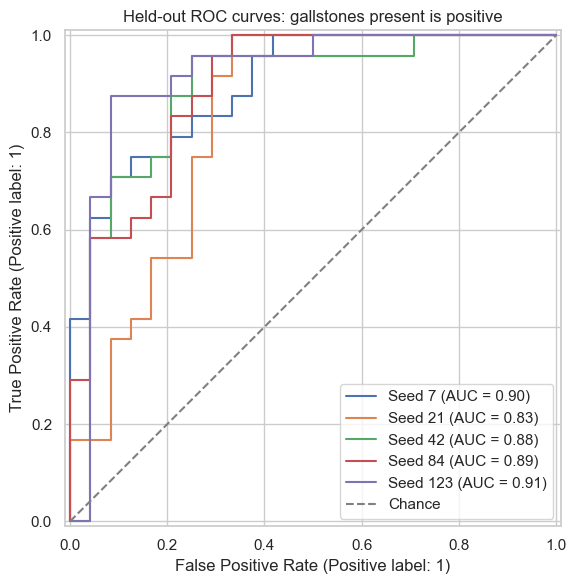

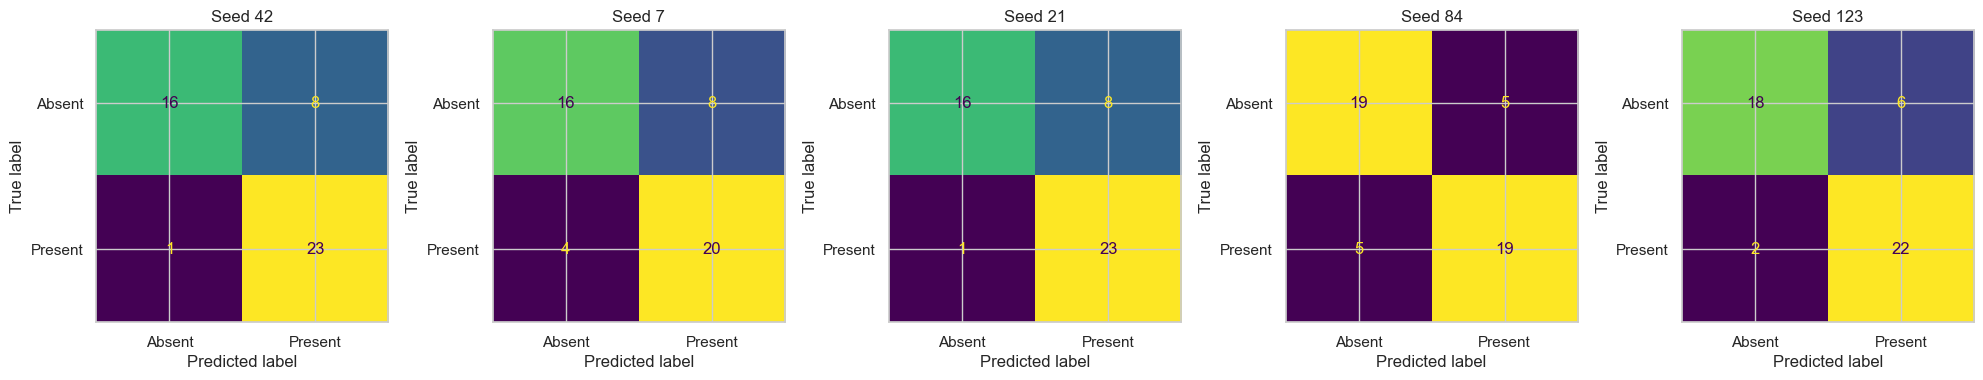

In [8]:
report_metrics = ["accuracy", "roc_auc", "fnr"]
validation_summary = validation_metrics.melt(
    id_vars=["seed", "selection", "model"], value_vars=report_metrics,
    var_name="metric", value_name="value"
).groupby(["selection", "model", "metric"]).value.agg(
    n_seeds="count", mean="mean", variance="var", std="std").reset_index()
test_summary = test_metrics[report_metrics].agg(["count", "mean", "var", "std"]).T
test_summary = test_summary.rename(columns={"count": "n_seeds", "var": "variance"})
validation_summary.to_csv(OUTPUT / "validation_summary.csv", index=False)
test_summary.to_csv(OUTPUT / "test_summary.csv", index_label="metric")
display(validation_summary, test_summary)

fig, ax = plt.subplots(figsize=(8, 6))
for seed, rows in test_predictions.groupby("seed"):
    RocCurveDisplay.from_predictions(rows.actual_present, rows.probability_present,
                                    name=f"Seed {seed}", ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.set_title("Held-out ROC curves: gallstones present is positive")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT / "test_roc_curves.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(SEEDS), figsize=(4 * len(SEEDS), 4), squeeze=False)
for ax, seed in zip(axes.ravel(), SEEDS):
    rows = test_predictions.loc[test_predictions.seed == seed]
    ConfusionMatrixDisplay.from_predictions(rows.actual_present, rows.predicted_present,
        labels=[0, 1], display_labels=["Absent", "Present"], colorbar=False, ax=ax)
    ax.set_title(f"Seed {seed}")
fig.tight_layout()
fig.savefig(OUTPUT / "test_confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()


## 6. Error explanation and review

**False negative:** gallstones are present (source code 0), but the model predicts absent. **False positive:** gallstones are absent (source code 1), but the model predicts present. The tables identify high-confidence mistakes, cases near the decision threshold, and how continuous measurements differ between false negatives and correctly identified cases.

These are descriptive error diagnostics, not causal explanations or evidence that a measurement caused an individual prediction. Small subgroup counts and repeated patients across seeds limit interpretation. Test errors must not be used to retune this evaluation.


In [9]:
errors = test_predictions.loc[test_predictions.error_type != "Correct"].copy()
errors["error_explanation"] = np.where(
    errors.error_type == "FN",
    "Gallstones present but predicted absent: missed positive case.",
    "Gallstones absent but predicted present: false alarm.")
errors["wrong_class_probability"] = np.where(
    errors.actual_present == 1, 1 - errors.probability_present, errors.probability_present)
errors["distance_from_threshold"] = (errors.probability_present - THRESHOLD).abs()
errors = errors.sort_values("wrong_class_probability", ascending=False)
errors = errors.join(X, on="source_row")
errors.to_csv(OUTPUT / "error_review.csv", index=False)
display(errors[["seed", "source_row", "error_type", "probability_present",
                "wrong_class_probability", "error_explanation"]].head(20))

fn_profiles = []
for seed in SEEDS:
    rows = test_predictions.loc[test_predictions.seed == seed]
    fn_ids = rows.loc[rows.error_type == "FN", "source_row"]
    tp_ids = rows.loc[(rows.actual_present == 1) & (rows.predicted_present == 1), "source_row"]
    development = splits[seed]["train"].append(splits[seed]["validation"])
    for feature in continuous_columns(X):
        reference_sd = X.loc[development, feature].std()
        fn_median = X.loc[fn_ids, feature].median()
        tp_median = X.loc[tp_ids, feature].median()
        fn_profiles.append({"seed": seed, "feature": feature, "fn_count": len(fn_ids),
                            "tp_count": len(tp_ids), "fn_median": fn_median,
                            "tp_median": tp_median,
                            "difference_in_development_sd": ((fn_median - tp_median) / reference_sd
                                if pd.notna(reference_sd) and reference_sd > 0 else np.nan)})
fn_profiles = pd.DataFrame(fn_profiles)
fn_profiles.to_csv(OUTPUT / "false_negative_profiles.csv", index=False)
display(fn_profiles.assign(magnitude=lambda t: t.difference_in_development_sd.abs())
        .sort_values("magnitude", ascending=False).head(20))
print("Rows can appear in several test splits; error rows are not unique patients across seeds.")


,seed,source_row,error_type,probability_present,wrong_class_probability,error_explanation
3,42,178,FP,0.998873,0.998873,Gallstones absent but predicted present: false...
197,123,239,FP,0.995132,0.995132,Gallstones absent but predicted present: false...
45,42,117,FN,0.067516,0.932484,Gallstones present but predicted absent: misse...
152,84,299,FP,0.906352,0.906352,Gallstones absent but predicted present: false...
123,21,317,FP,0.898390,0.898390,Gallstones absent but predicted present: false...
30,42,309,FP,0.874490,0.874490,Gallstones absent but predicted present: false...
131,21,315,FP,0.874056,0.874056,Gallstones absent but predicted present: false...
39,42,174,FP,0.853568,0.853568,Gallstones absent but predicted present: false...
227,123,92,FN,0.160743,0.839257,Gallstones present but predicted absent: misse...
8,42,304,FP,0.814643,0.814643,Gallstones absent but predicted present: false...


,seed,feature,fn_count,tp_count,fn_median,tp_median,difference_in_development_sd,magnitude
27,42,gfr,1,23,11.340000,106.600,-5.706000,5.706000
87,21,alp,1,23,157.000000,70.000,3.720730,3.720730
25,42,alp,1,23,119.000000,62.000,2.349542,2.349542
74,21,bm,1,23,2.000000,3.100,-2.183213,2.183213
79,21,vma_kg,1,23,21.800000,30.600,-1.995226,1.995226
75,21,mm,1,23,37.400000,58.100,-1.948574,1.948574
84,21,triglyceride,1,23,297.000000,105.000,1.934969,1.934969
66,21,tbw,1,23,27.900000,43.100,-1.912407,1.912407
68,21,icw,1,23,15.400000,24.300,-1.648740,1.648740
30,42,vitamin_d,1,23,10.966667,26.980,-1.596631,1.596631


Rows can appear in several test splits; error rows are not unique patients across seeds.


## 7. Reproducibility and output files

Each seed folder contains split membership, training-selected feature tables, the final selected-feature table, test predictions and the serialized pipeline. The top-level output directory contains per-seed metrics, mean/sample-variance summaries, figures, error review and experiment metadata. Import the local utils module before loading these pipelines in a new Python session.


In [10]:
config = {"seeds": SEEDS, "models": MODELS, "selectors": SELECTORS, "top_k_source_features": TOP_K,
          "split": [0.70, 0.15, 0.15], "threshold": THRESHOLD, "variance_ddof": 1,
          "source_labels": {"0": "present", "1": "absent"},
          "model_labels": {"0": "absent", "1": "present"},
          "selection_rule": "validation ROC-AUC descending, accuracy descending, FNR ascending, selector/model name",
          "winners": {str(seed): {k: v for k, v in info.items() if k != "training_model"}
                      for seed, info in winners.items()},
          "versions": {name: __import__(name).__version__ for name in ["numpy", "pandas", "sklearn", "xgboost", "lightgbm"]}}
(OUTPUT / "run_config.json").write_text(json.dumps(config, indent=2) + "\n")
assert len(test_metrics) == len(SEEDS)
assert len(validation_metrics) == len(SEEDS) * len(MODELS) * len(SELECTORS)
assert np.isfinite(test_metrics[report_metrics].to_numpy()).all()
print(f"Saved models, evaluations and error analysis to {OUTPUT}")


Saved models, evaluations and error analysis to /Users/quyduong106/projects/INFOSYS722/Iteration3_OpenStack/output/notebook_evaluation


## 8. Feature importance and transformation visualization

This additional section complements the earlier random-forest importance plot. It uses the **training-fitted validation winners**, whose pipelines include feature selection, Yeo-Johnson and standardization. It does not refit transformations or inspect test data.

### 8.1 Importance of source features in the transformed pipelines

Permutation importance measures the decrease in **validation ROC-AUC** when one source feature is shuffled through the complete fitted pipeline. This keeps one-hot encoded columns grouped under their original feature. Features excluded by selection have zero importance. Negative importance is retained: shuffling can improve validation scores by chance.

The bars show the mean across five seeds; error bars show sample standard deviation between seed-level means, not confidence intervals. Winners and selected features can differ between seeds. Because validation also selected the winners, these are descriptive diagnostics of that procedure, not independent importance estimates. Correlated predictors can share or mask importance.


,mean_importance,std_importance,n_seeds
feature,,,
crp,0.107604,0.049475,5
bm,0.063229,0.051444,5
ecf_tbw,0.054826,0.023922,5
vitamin_d,0.030729,0.015889,5
icw,0.019375,0.034978,5
protein_pct,0.019201,0.013172,5
ecw,0.016632,0.015568,5
hfa,0.016111,0.015522,5
height,0.014410,0.022394,5


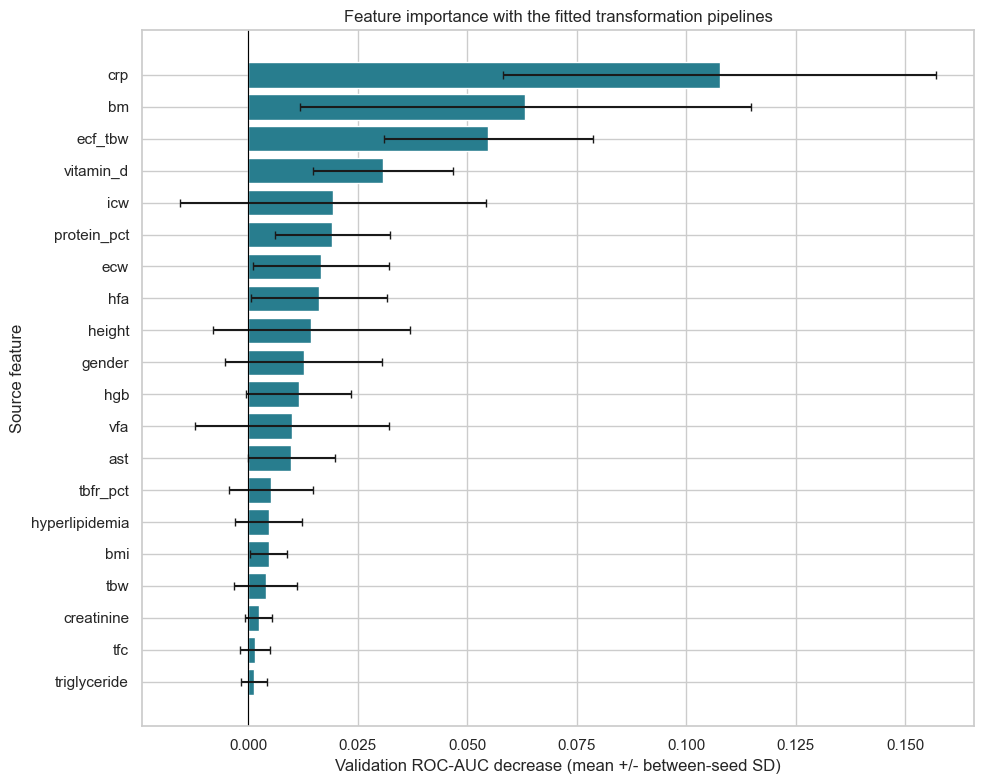

In [11]:
from sklearn.inspection import permutation_importance

VISUALIZATION_OUTPUT = OUTPUT / "feature_visualizations"
VISUALIZATION_OUTPUT.mkdir(exist_ok=True)
permutation_rows = []
for seed in SEEDS:
    validation_index = splits[seed]["validation"]
    training_model = winners[seed]["training_model"]
    result = permutation_importance(
        training_model, X.loc[validation_index], y.loc[validation_index],
        scoring="roc_auc", n_repeats=10, random_state=seed, n_jobs=1)
    for feature, mean, std in zip(X.columns, result.importances_mean, result.importances_std):
        permutation_rows.append({"seed": seed, "feature": feature,
                                 "model": winners[seed]["model"],
                                 "selection": winners[seed]["selection"],
                                 "importance": mean, "within_seed_std": std})
pipeline_importance = pd.DataFrame(permutation_rows)
pipeline_importance_summary = pipeline_importance.groupby("feature").importance.agg(
    mean_importance="mean", std_importance="std", n_seeds="count"
).sort_values("mean_importance", ascending=False)
pipeline_importance.to_csv(VISUALIZATION_OUTPUT / "permutation_importance_per_seed.csv", index=False)
pipeline_importance_summary.to_csv(VISUALIZATION_OUTPUT / "permutation_importance_summary.csv")
display(pipeline_importance_summary.head(20))

importance_plot = pipeline_importance_summary.head(20).sort_values("mean_importance")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(importance_plot.index, importance_plot.mean_importance,
        xerr=importance_plot.std_importance.fillna(0), capsize=3, color="#287D8E")
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Feature importance with the fitted transformation pipelines",
       xlabel="Validation ROC-AUC decrease (mean +/- between-seed SD)", ylabel="Source feature")
fig.tight_layout()
fig.savefig(VISUALIZATION_OUTPUT / "transformed_pipeline_importance.png", dpi=180, bbox_inches="tight")
plt.show()


### 8.2 Before and after Yeo-Johnson and standardization

The panels below use one seed's training-fitted pipeline and training rows. Change `VIS_SEED` to inspect another seed. For a stacking winner, `VIS_BASE_MODEL` selects the fitted base pipeline to inspect.

The first column shows selected continuous measurements after imputation in their original units. The second applies the **already fitted Yeo-Johnson** transformation. The third applies the **already fitted StandardScaler**. No fitting occurs in this section. Standardization changes location and scale, not skewness; the last two columns should have the same skewness. Encoded categorical fields are excluded.

All selected continuous features are displayed in batches of five, ordered by their seed-specific permutation importance. The statistics table also reports the learned Yeo-Johnson lambda. Importance is predictive association, not a clinical or causal explanation.


In [12]:
VIS_SEED = SEEDS[0]
VIS_BASE_MODEL = "logistic"
visual_model = winners[VIS_SEED]["training_model"]
if hasattr(visual_model, "named_estimators_"):
    visual_pipeline = visual_model.named_estimators_[VIS_BASE_MODEL]
    visual_model_label = f"stacking / {VIS_BASE_MODEL}"
else:
    visual_pipeline = visual_model
    visual_model_label = winners[VIS_SEED]["model"]

visual_training = X.loc[splits[VIS_SEED]["train"]]
imputed_training = visual_pipeline.named_steps["impute"].transform(visual_training)
selected_training = visual_pipeline.named_steps["select"].transform(imputed_training)
visual_continuous = continuous_columns(selected_training)
assert not set(visual_continuous).intersection(
    {"gender", "comorbidity", "cad", "hypothyroidism", "hyperlipidemia", "dm", "hfa"})
if not visual_continuous:
    raise ValueError("This pipeline selected no continuous features to visualize.")

continuous_transform = visual_pipeline.named_steps["transform"].named_transformers_["continuous"]
fitted_yj = continuous_transform.named_steps["yeo_johnson"]
fitted_scaler = continuous_transform.named_steps["standardize"]
original_values = selected_training[visual_continuous]
yj_values = pd.DataFrame(fitted_yj.transform(original_values),
                         index=original_values.index, columns=visual_continuous)
standardized_values = pd.DataFrame(fitted_scaler.transform(yj_values.to_numpy()),
                                   index=original_values.index, columns=visual_continuous)
np.testing.assert_allclose(standardized_values.mean(), 0, atol=1e-8)
varying = standardized_values.std(ddof=0) > 1e-8
np.testing.assert_allclose(standardized_values.std(ddof=0)[varying], 1, atol=1e-8)
np.testing.assert_allclose(yj_values.skew(), standardized_values.skew(), atol=1e-8, equal_nan=True)

transformation_statistics = pd.DataFrame({
    "yeo_johnson_lambda": fitted_yj.lambdas_,
    "original_mean": original_values.mean(),
    "original_std": original_values.std(ddof=0),
    "original_skew": original_values.skew(),
    "yeo_johnson_mean": yj_values.mean(),
    "yeo_johnson_std": yj_values.std(ddof=0),
    "yeo_johnson_skew": yj_values.skew(),
    "standardized_mean": standardized_values.mean(),
    "standardized_std": standardized_values.std(ddof=0),
    "standardized_skew": standardized_values.skew(),
}, index=visual_continuous)
display(transformation_statistics)
transformation_statistics.to_csv(
    VISUALIZATION_OUTPUT / f"seed_{VIS_SEED}_transformation_statistics.csv", index_label="feature")


,yeo_johnson_lambda,original_mean,original_std,original_skew,yeo_johnson_mean,yeo_johnson_std,yeo_johnson_skew,standardized_mean,standardized_std,standardized_skew
age,0.751826,47.600897,12.592168,0.246777,23.168466,4.828654,0.012895,-5.994209e-16,1.0,0.012895
height,1.301391,167.466368,10.071382,-0.053986,606.613677,47.187495,-0.017669,-3.176333e-16,1.0,-0.017669
weight,0.099485,80.583408,15.761642,0.524793,5.497139,0.297706,-0.000363,9.399556e-16,1.0,-0.000363
bmi,-0.190962,28.805830,5.371684,0.795262,2.488358,0.092375,-0.004089,-1.863980e-15,1.0,-0.004089
tbw,-0.005635,40.893722,7.843020,0.330212,3.678890,0.183301,0.000310,-1.561282e-15,1.0,0.000310
ecw,0.714639,17.057399,3.197536,0.101716,9.630300,1.404459,-0.020387,-2.867661e-16,1.0,-0.020387
icw,0.252069,23.720179,5.052238,0.242119,4.902359,0.460689,-0.015689,-3.982863e-17,1.0,-0.015689
ecf_tbw,3.374701,41.972735,3.163171,-0.688216,98271.264685,23037.696071,0.023216,4.142177e-16,1.0,0.023216
tbfr_pct,0.850739,28.021704,8.362762,0.091125,19.345932,5.086288,-0.025431,-2.628689e-16,1.0,-0.025431
lm_pct,1.261838,71.919686,8.370203,-0.094230,177.263156,25.672788,-0.019535,6.372581e-17,1.0,-0.019535


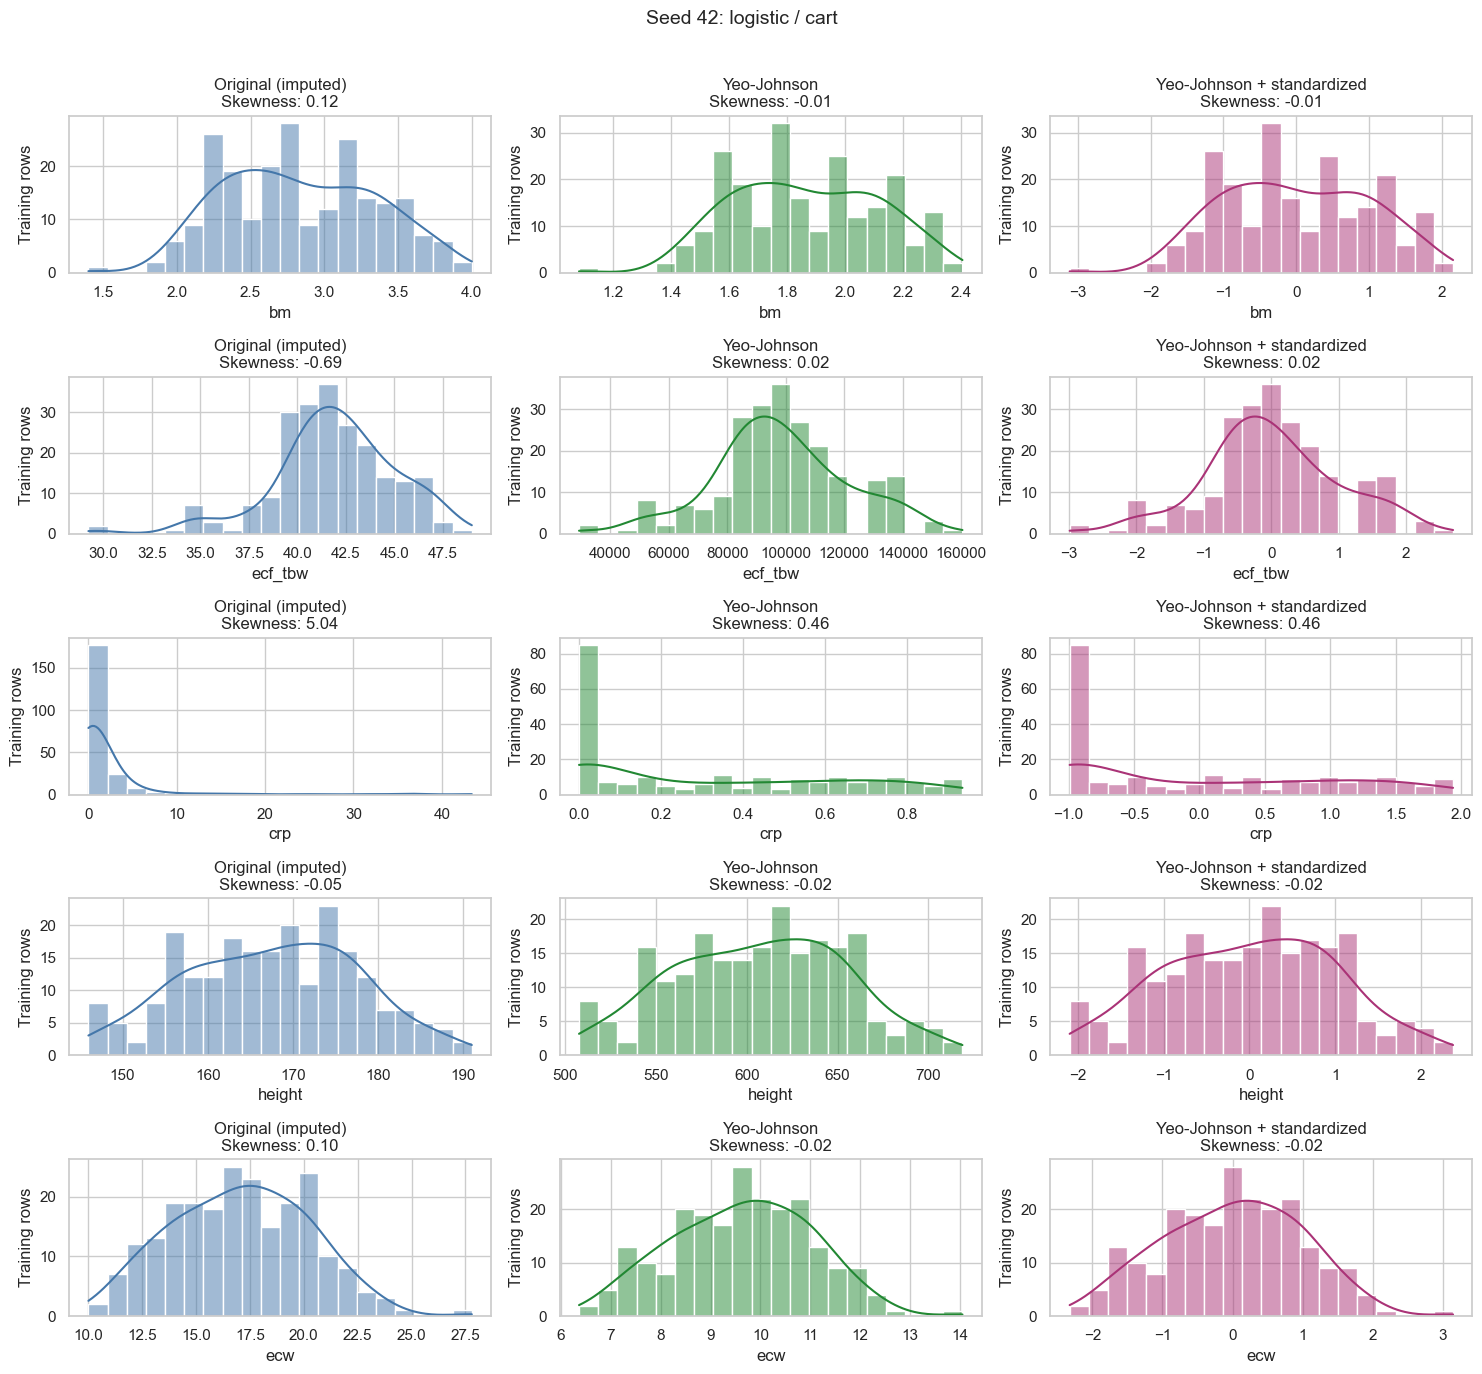

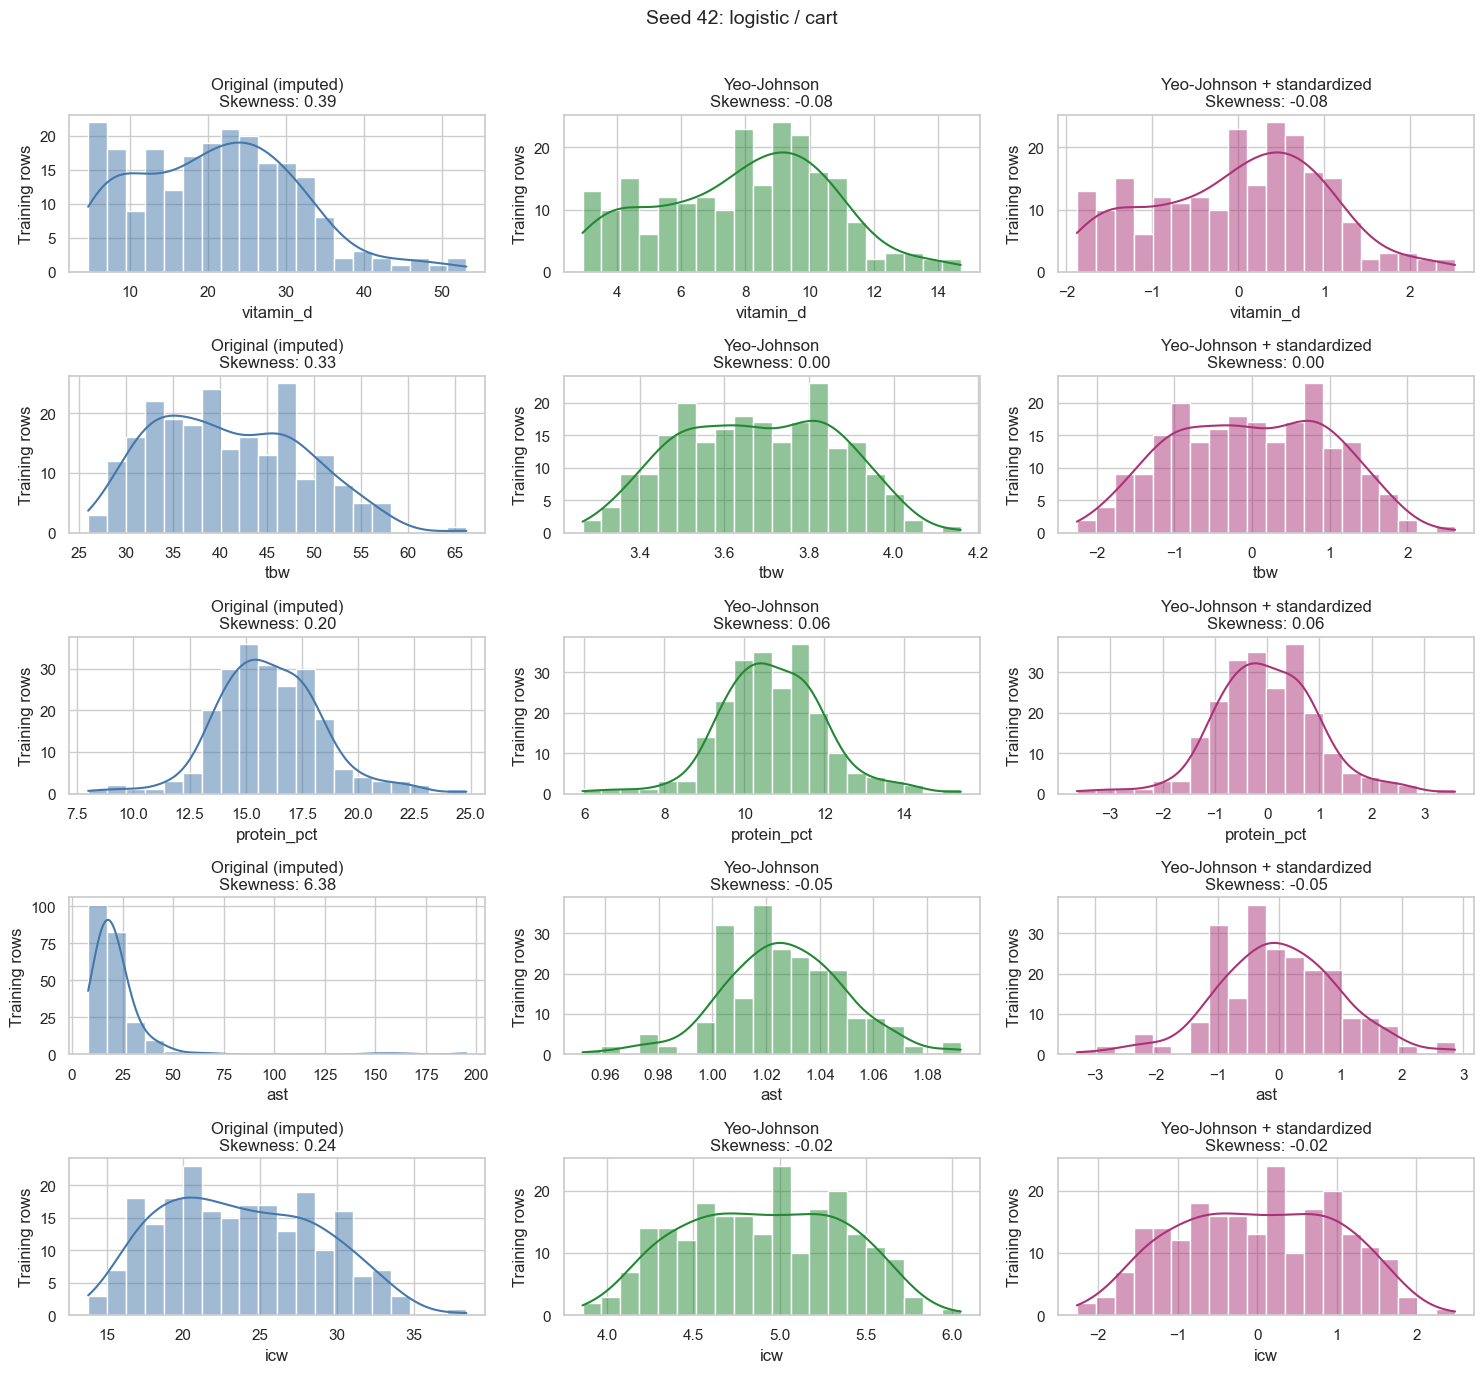

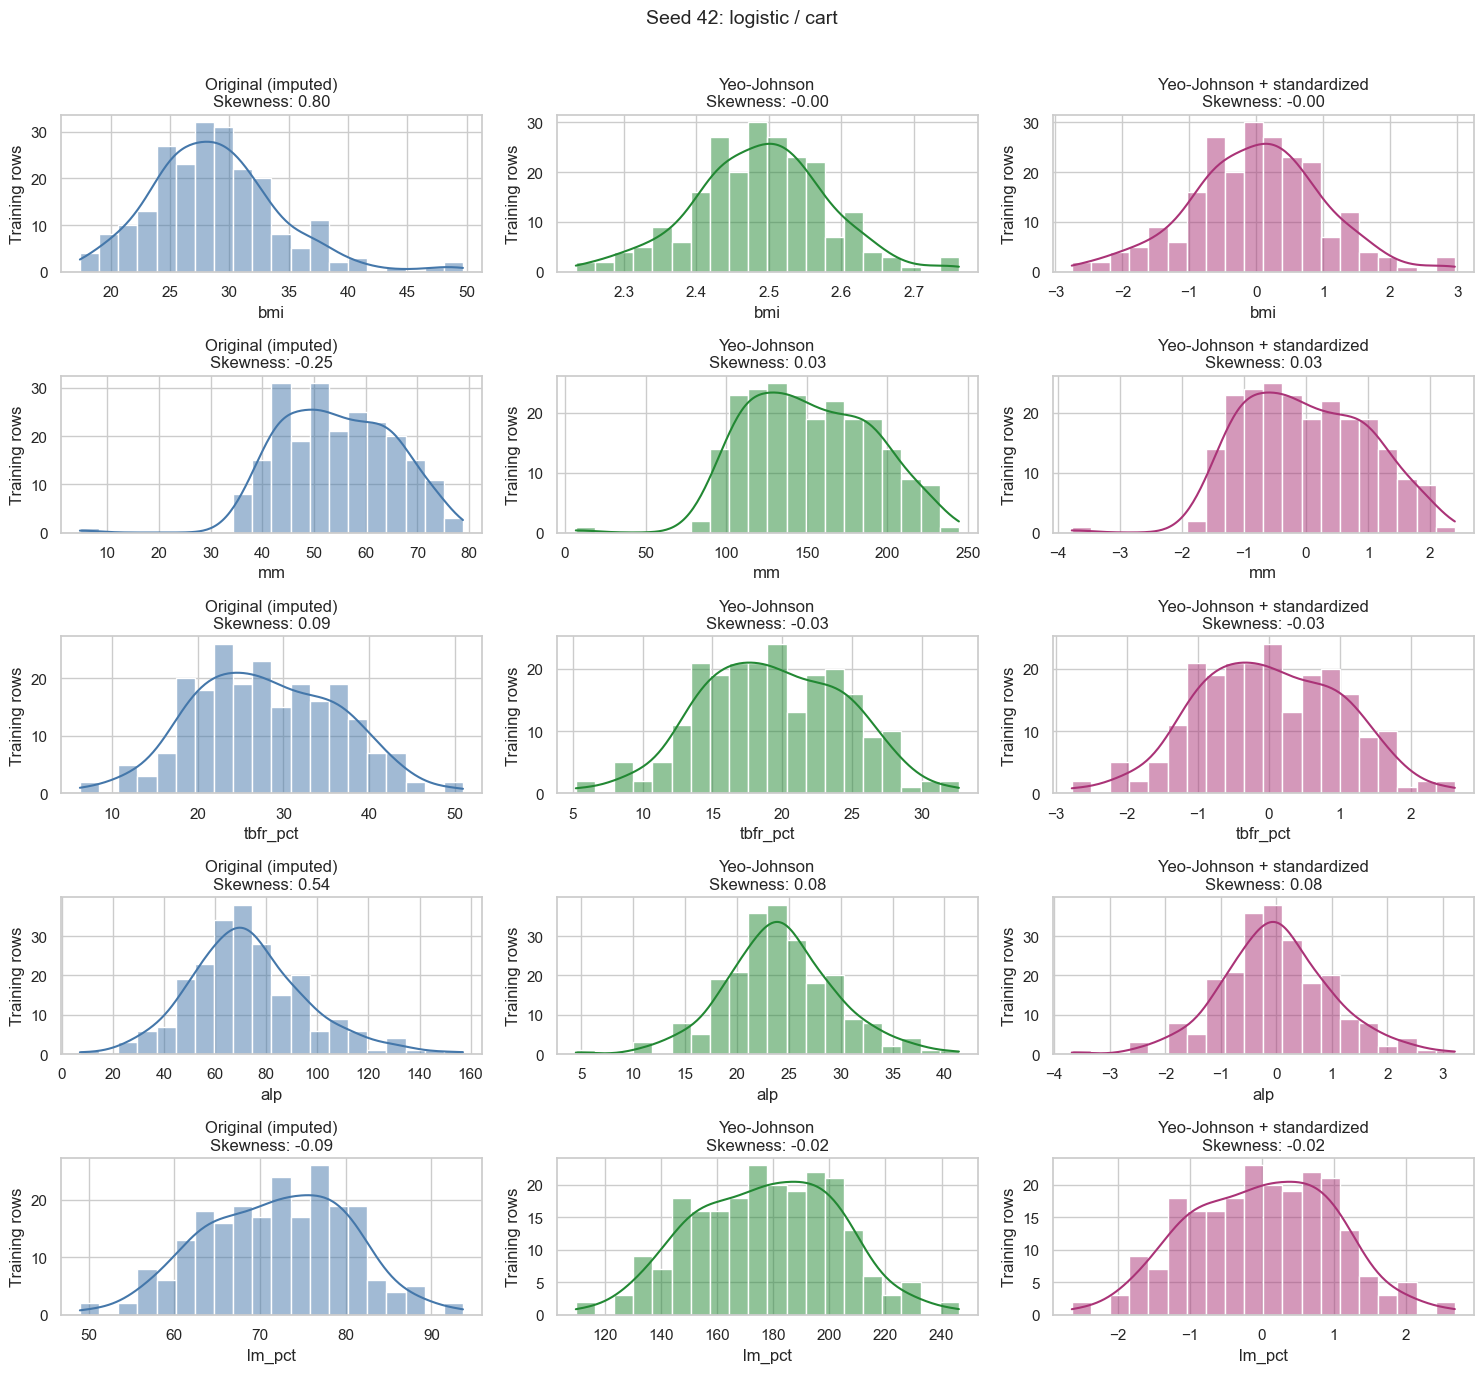

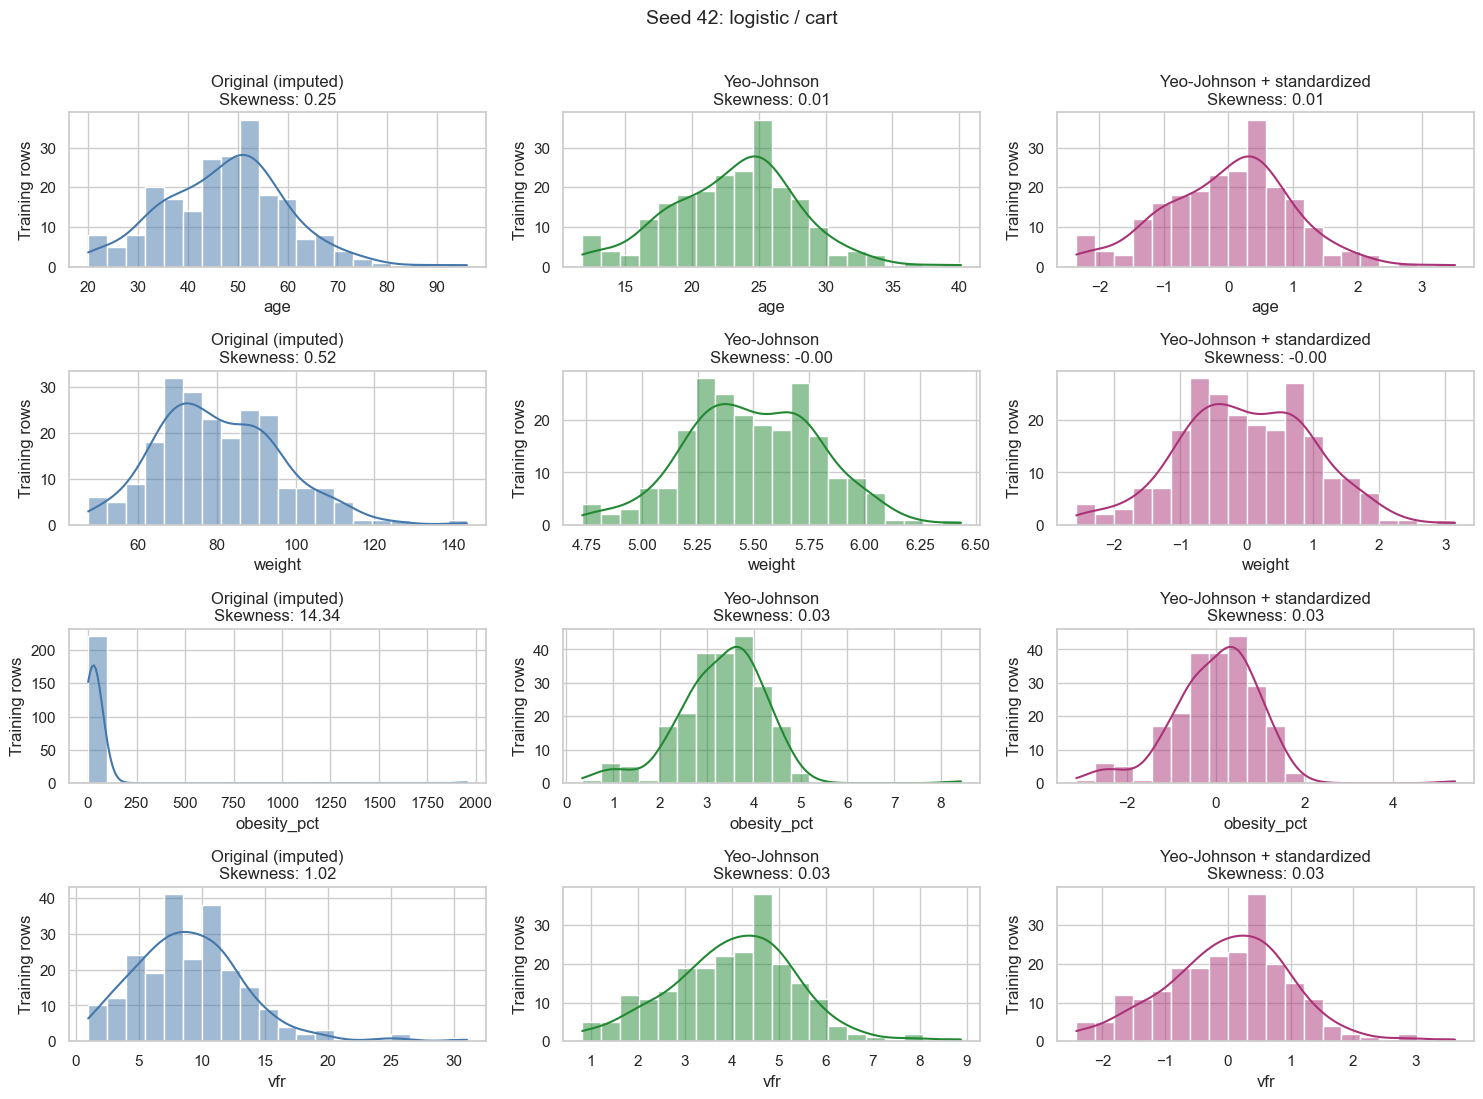

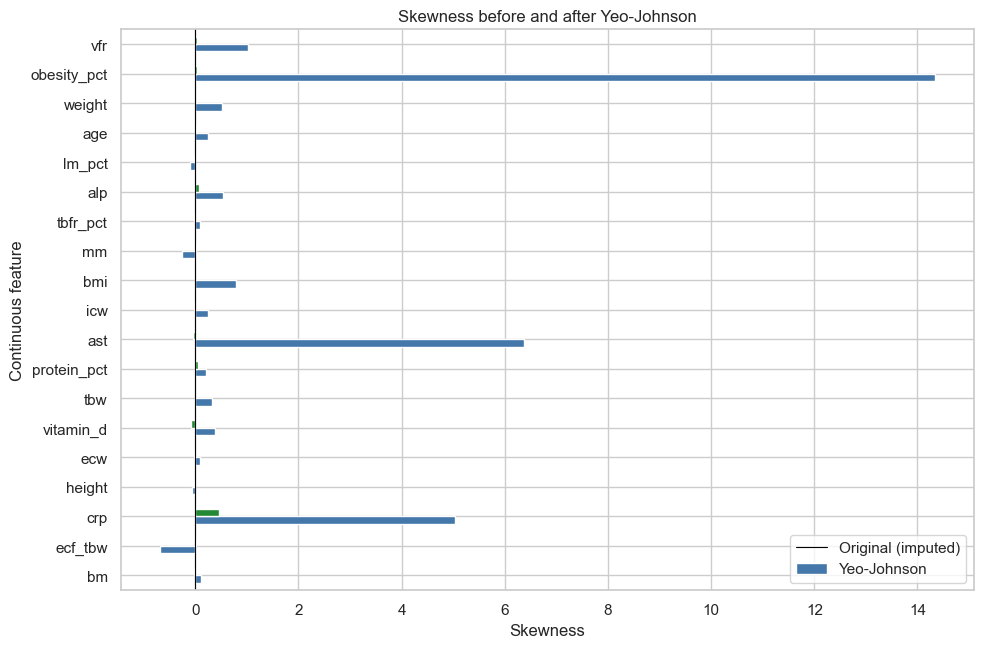

Saved importance and transformation visualizations to /Users/quyduong106/projects/INFOSYS722/Iteration3_OpenStack/output/notebook_evaluation/feature_visualizations


In [13]:
seed_importance = pipeline_importance.loc[pipeline_importance.seed == VIS_SEED].set_index("feature").importance
visual_features = seed_importance.reindex(visual_continuous).sort_values(ascending=False).index.tolist()
stages = [("Original (imputed)", original_values, "#4477AA"),
          ("Yeo-Johnson", yj_values, "#228833"),
          ("Yeo-Johnson + standardized", standardized_values, "#AA3377")]
for start in range(0, len(visual_features), 5):
    batch = visual_features[start:start + 5]
    fig, axes = plt.subplots(len(batch), 3, figsize=(15, 2.8 * len(batch)), squeeze=False)
    for row, feature in enumerate(batch):
        for column, (label, values, color) in enumerate(stages):
            ax = axes[row, column]
            sns.histplot(values[feature], bins=20, kde=values[feature].nunique() > 1,
                         color=color, ax=ax)
            ax.set(title=f"{label}\nSkewness: {values[feature].skew():.2f}",
                   xlabel=feature, ylabel="Training rows")
    fig.suptitle(f"Seed {VIS_SEED}: {visual_model_label} / {winners[VIS_SEED]['selection']}",
                 fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig(VISUALIZATION_OUTPUT / f"seed_{VIS_SEED}_transformations_{start // 5 + 1}.png",
                dpi=150, bbox_inches="tight")
    plt.show()

skew_plot = transformation_statistics.loc[visual_features, ["original_skew", "yeo_johnson_skew"]]
ax = skew_plot.plot.barh(figsize=(10, max(5, 0.35 * len(skew_plot))),
                        color=["#4477AA", "#228833"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Skewness before and after Yeo-Johnson", xlabel="Skewness", ylabel="Continuous feature")
ax.legend(["Original (imputed)", "Yeo-Johnson"])
ax.figure.tight_layout()
ax.figure.savefig(VISUALIZATION_OUTPUT / f"seed_{VIS_SEED}_skewness.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved importance and transformation visualizations to {VISUALIZATION_OUTPUT}")
